# SVM cây dược liệu — đánh giá trước và sau tối ưu
Huỳnh Gia Huy · 28/10/2026.

Notebook đọc **kết quả đã chạy thật**; không huấn luyện hoặc chấm test lại. Dữ liệu [BDMediLeaves 6 loài](https://data.mendeley.com/datasets/t9rns2gmr3/1), Islam và cộng sự, CC BY 4.0. Học sâu chưa được thực hiện.

In [1]:
from pathlib import Path
import json, hashlib
import pandas as pd
import numpy as np
from sklearn.metrics import f1_score, accuracy_score
from IPython.display import display, Image
candidates=[Path.cwd(),Path.cwd().parent]
ROOT=next(p for p in candidates if (p/'data/audit/manifest.csv').exists())
R=ROOT/'results/phase2'
manifest=pd.read_csv(ROOT/'data/audit/manifest.csv')
frozen=json.loads((R/'final/frozen_selection.json').read_text())
assert hashlib.sha256((ROOT/'data/audit/manifest.csv').read_bytes()).hexdigest()==frozen['manifest_sha256']
assert manifest.pixel_sha256.nunique()==len(manifest)
assert manifest.groupby('group').split.nunique().max()==1
display(pd.crosstab(manifest.label,manifest.split))

split,development,test
label,,
Centella Asiatica,132,32
Justicia Adhatoda,130,32
Kalanchoe Pinnata,129,33
Mikania Micrantha,128,32
Phyllanthus Emblica,125,32
Terminalia Arjuna,134,33


## Chọn đặc trưng bằng development
CV tham gia lựa chọn nên không phải đánh giá độc lập. Bộ 126 chiều được chọn trước test.

,feature_id,dimension,mean_cv_macro_f1
0,v1,958,0.752085
1,v1_no_color,910,0.715000
2,texture128,126,0.856296
3,enhanced128,1890,0.780364
4,center128,1890,0.785036


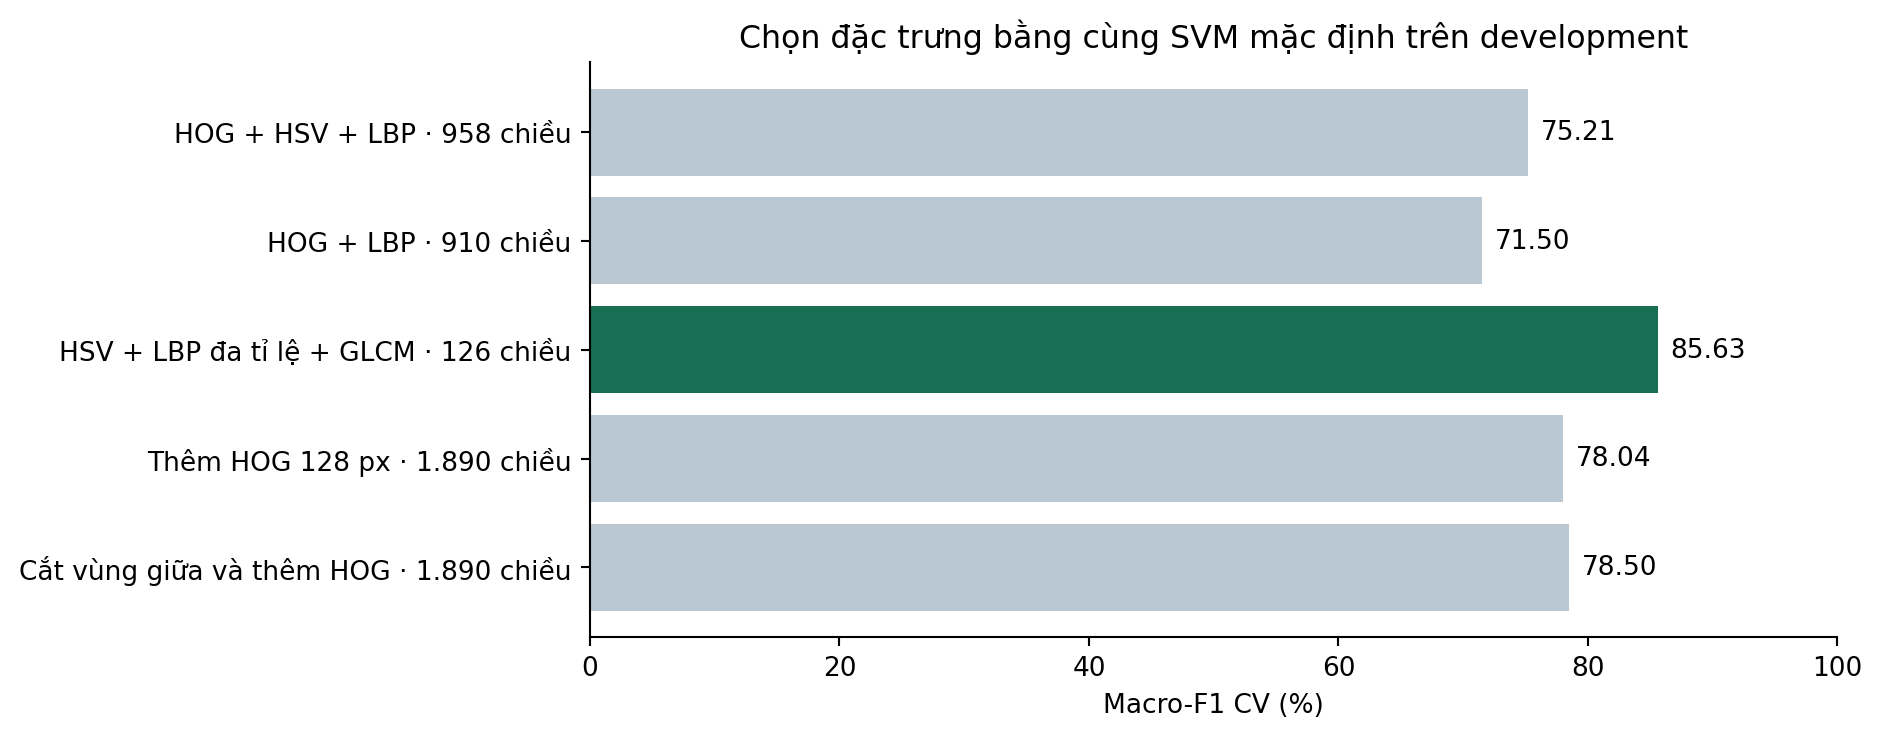

In [2]:
ablation=pd.read_csv(R/'ablation/summary.csv')
display(ablation[['feature_id','dimension','mean_cv_macro_f1']])
display(Image(filename=str(R/'figures/feature_ablation.png'),width=850))

## Hai phương pháp cùng ngân sách
40 trial × 5 seed × 2 phương pháp = 400. Chọn phương pháp theo mean best-CV, giữ cả các seed kém.

,method,seed,best_cv_macro_f1,seconds
0,random,11,0.869862,3.280279
1,random,29,0.879173,3.375650
2,random,47,0.861226,2.963683
3,random,71,0.870874,3.259853
4,random,101,0.879424,3.032405
5,tpe,11,0.883319,3.666955
6,tpe,29,0.883319,3.677673
7,tpe,47,0.883319,3.426363
8,tpe,71,0.845709,2.583879
9,tpe,101,0.846825,2.619467


,mean,std
method,,
random,0.872112,0.007557
tpe,0.868498,0.020298


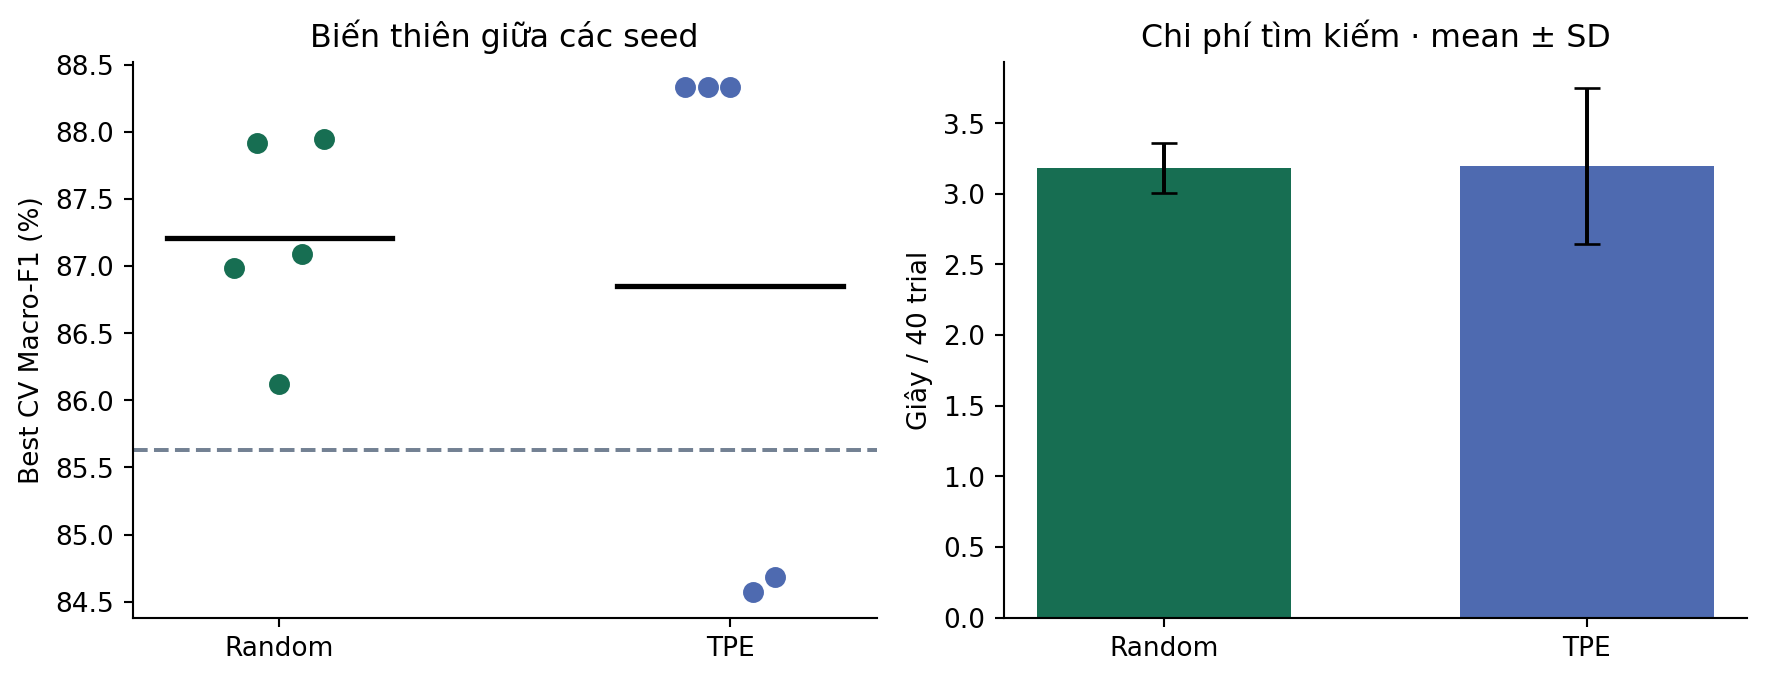

In [3]:
trials=pd.read_csv(R/'hpo/trials.csv')
assert len(trials)==400
assert (trials.groupby(['method','seed']).size()==40).all()
summary=pd.DataFrame(json.loads((R/'hpo/summary.json').read_text()))
display(summary[['method','seed','best_cv_macro_f1','seconds']])
display(summary.groupby('method').best_cv_macro_f1.agg(['mean','std']))
display(Image(filename=str(R/'figures/stability_runtime.png'),width=850))

Lựa chọn trước test: random
{
  "method": "random",
  "seed": 101,
  "best_cv_macro_f1": 0.8794242726646431,
  "params": {
    "kernel": "rbf",
    "C": 13.28777377006487,
    "gamma": 0.006029953818540779
  },
  "best_trial": 24,
  "fold_scores": [
    0.8657202717628106,
    0.9028900312902385,
    0.8696625149408801
  ],
  "seconds": 3.032405436999852
}


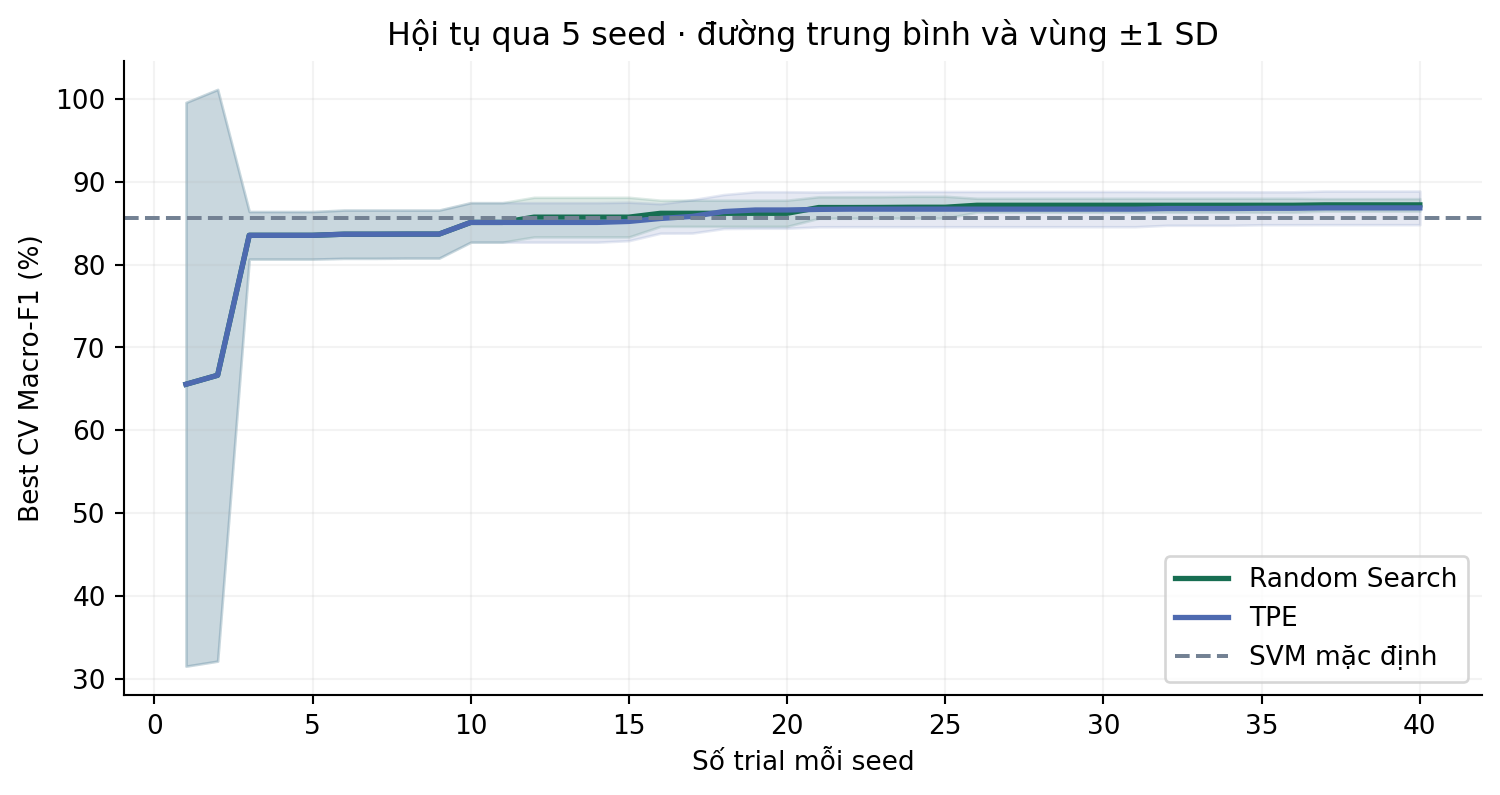

In [4]:
assert frozen['test_evaluated_at_freeze'] is False
assert frozen['selected_method']=='random'
print('Lựa chọn trước test:',frozen['selected_method'])
print(json.dumps(frozen['best_by_method']['random'],indent=2))
display(Image(filename=str(R/'figures/convergence.png'),width=850))

## Tính lại chỉ số từ dự đoán đã lưu
Cùng 194 ảnh, mô hình chỉ fit trên 778 development. Không gọi fit hoặc predict trong notebook. TPE test cao hơn không thay đổi quyết định trước test.

,model,test_macro_f1,test_accuracy,train_macro_f1
0,v1_default,0.829577,0.829897,0.996158
1,baseline,0.830562,0.829897,0.970545
2,random,0.887053,0.886598,1.000000
3,tpe,0.891891,0.891753,1.000000


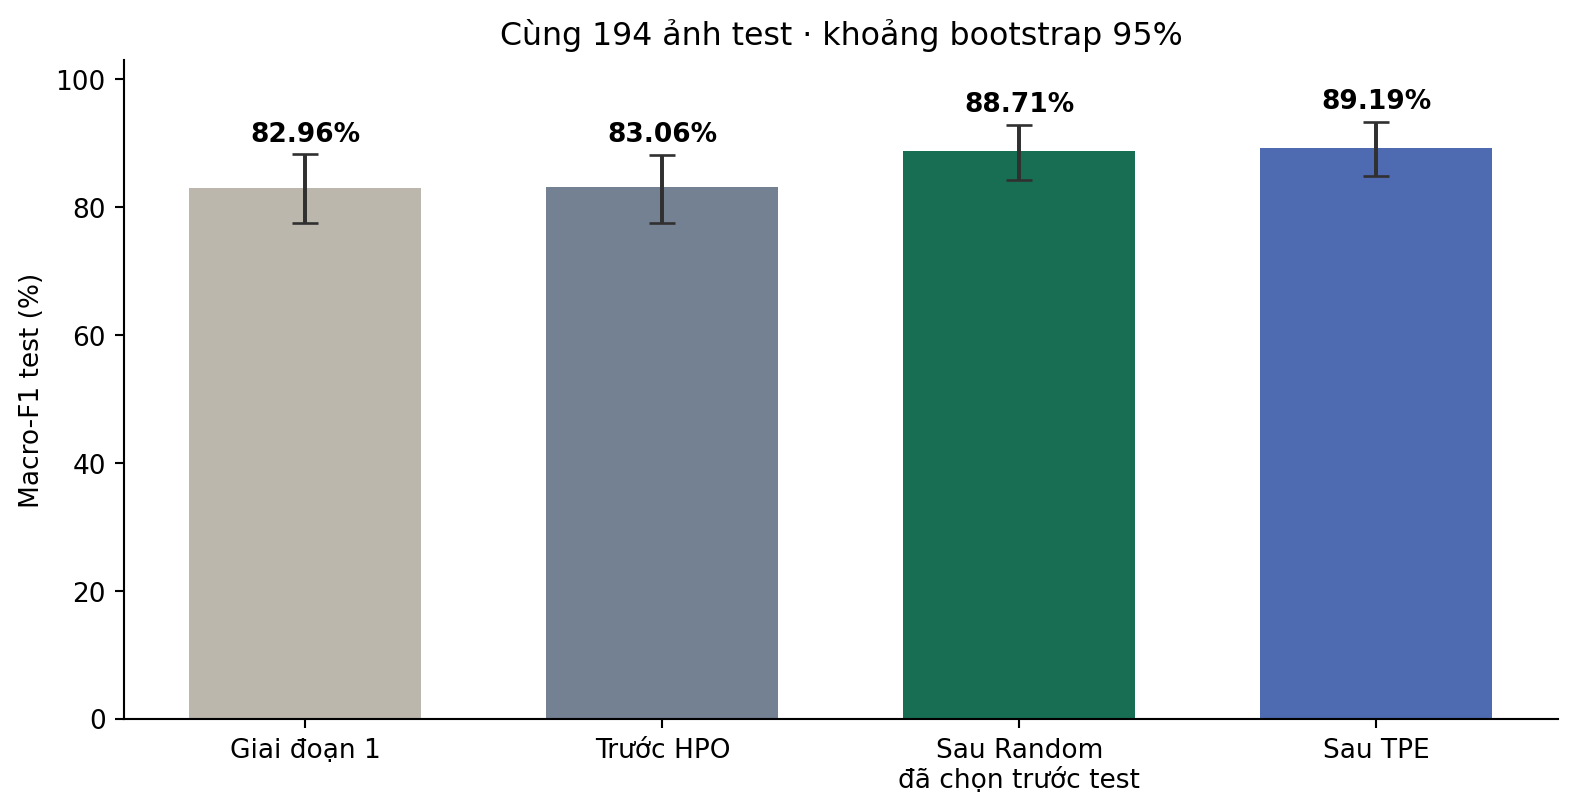

In [5]:
pred=pd.read_csv(R/'evaluation/predictions.csv')
metrics=json.loads((R/'evaluation/metrics.json').read_text())
rows=[]
for name,m in metrics.items():
    f1=f1_score(pred.label,pred[name],average='macro')
    acc=accuracy_score(pred.label,pred[name])
    assert abs(f1-m['test_macro_f1'])<1e-12
    assert abs(acc-m['test_accuracy'])<1e-12
    rows.append({'model':name,'test_macro_f1':f1,'test_accuracy':acc,'train_macro_f1':m['train_macro_f1']})
display(pd.DataFrame(rows))
display(Image(filename=str(R/'figures/before_after_test.png'),width=850))

Delta Macro-F1 (điểm phần trăm): 5.649117392093872
Khoảng 95% ghép cặp: [2.0076433388215675, 9.75676776643713]
Sửa lỗi: 13 ; lỗi mới: 2


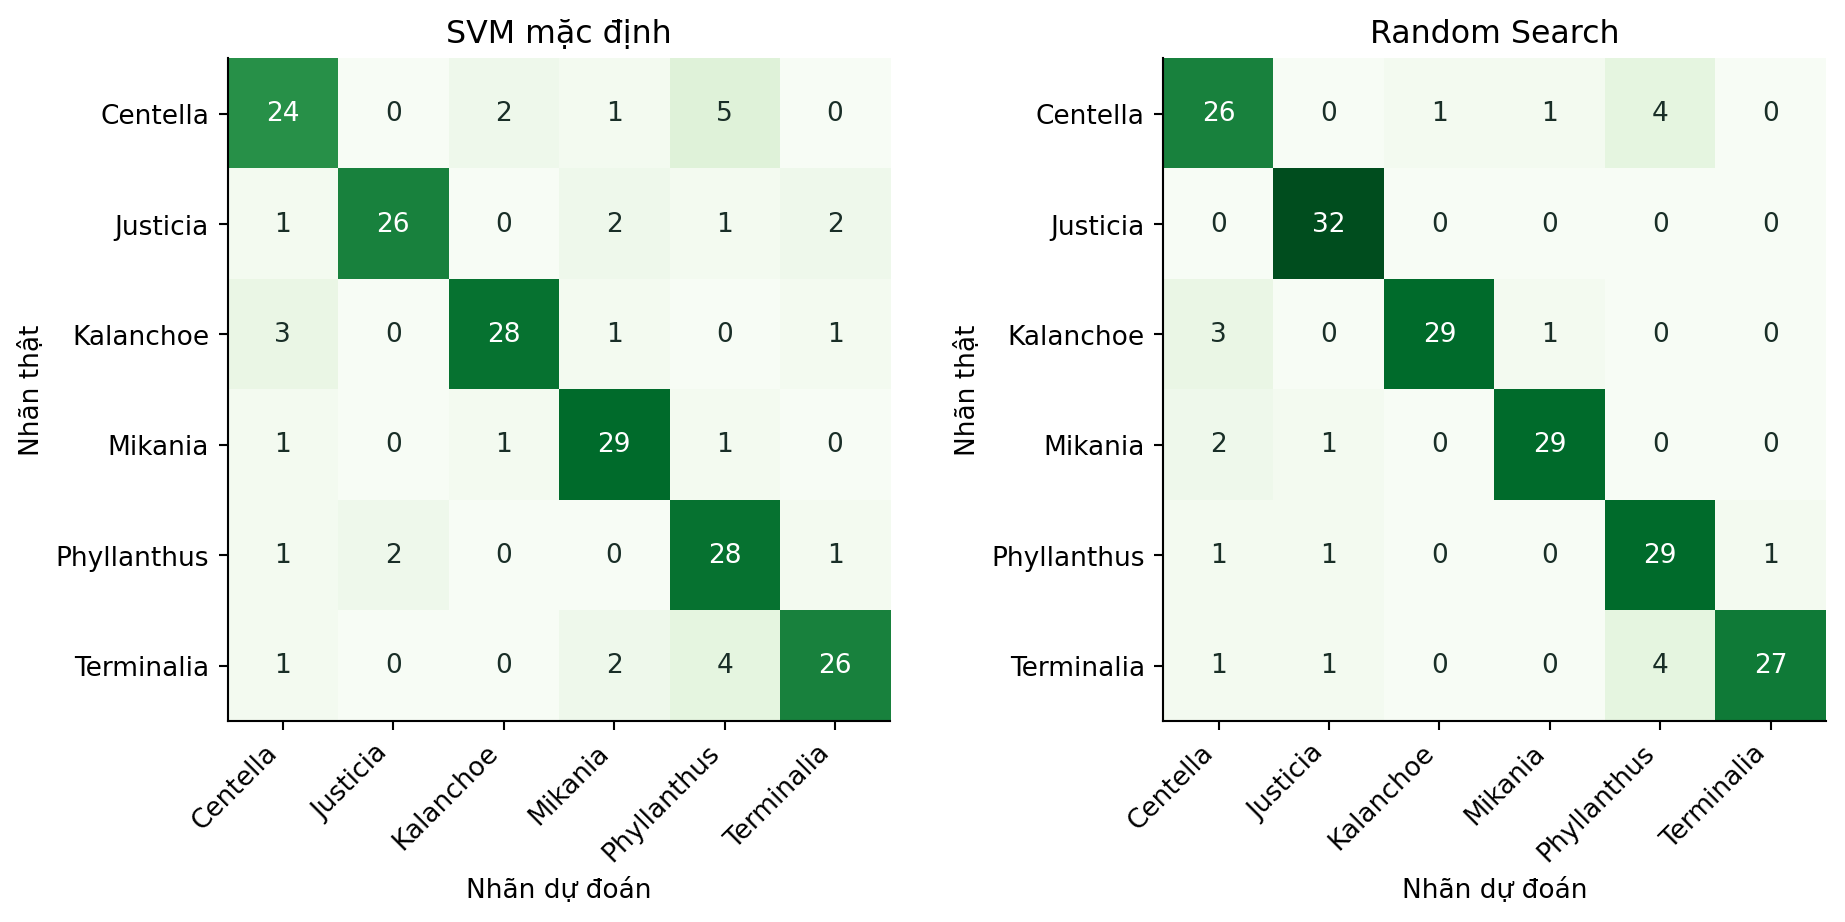

In [6]:
comparison=json.loads((R/'evaluation/comparison.json').read_text())
assert comparison['selected_before_test']==frozen['selected_method']
print('Delta Macro-F1 (điểm phần trăm):',100*comparison['delta_test_macro_f1'])
print('Khoảng 95% ghép cặp:',[100*x for x in comparison['bootstrap']['selected_minus_baseline_macro_f1_ci95']])
print('Sửa lỗi:',comparison['corrected_errors'],'; lỗi mới:',comparison['new_errors'])
display(Image(filename=str(R/'figures/confusion_before_after.png'),width=850))

## Giới hạn và bước tiếp theo
Nhóm gần trùng không phải ID cây/phiên chụp. Test đã mở không còn là đánh giá kín cho thiết kế mới. Train F1=100% vẫn có nguy cơ quá khớp; chưa có unknown. Đổi đặc trưng tăng CV mạnh nhưng test mặc định chỉ 82,96% → 83,06%. Cần thu ảnh ngoài miền có nhãn kiểm định trước khi phát triển CNN + SVM hoặc fine-tune.

## Tái lập tại terminal
```bash
python -m pip install -r requirements.txt
python -m src.reproduce --out results/reproduction_01
python -m unittest discover -s tests -v
python -m src.predict "anh_la.jpg" --compare
```
Dùng thư mục kết quả mới. Xem README cho Windows. Notebook đã thực thi tuần tự bằng IPython cùng tiến trình; chưa kiểm thử giao diện Jupyter/VS Code.